# 📊 Automação e Escalabilidade de Pipelines de Big Data para Diagnóstico de Burnout Corporativo

**Módulo:** Data Science — 2º Semestre de 2026  
**Disciplina:** Big Data & Processamento Distribuído (Prof. Gabriel)  

---

## 📌 Contextualização do Problema & Os 5 Vs de Big Data
O objetivo deste projeto é identificar preventivamente o risco de esgotamento profissional (Burnout) em equipes corporativas por meio de um pipeline de dados distribuído e automatizado.

* **Volume:** Processamento de grandes históricos de ponto eletrônico, registros de chamados e pesquisas de clima corporativo.
* **Velocidade:** Ingestão contínua e automatizada de dados de carga de trabalho e telemetria.
* **Variedade:** Integração de dados estruturados (ponto eletrônico, departamentos) e semiestruturados (logs de chamados fora de horário).
* **Veracidade:** Tratamento de inconsistências, eliminação de duplicidades e tratamento de valores ausentes via Arquitetura Medallion (Camadas Bronze, Silver e Gold).
* **Valor:** Conversão de dados brutos em indicadores preditivos e ações estratégicas de RH alinhadas ao **ODS 8 da ONU (Trabalho Decente e Crescimento Econômico)**.

---

## 📖 Dicionário de Dados Oficial

| Nome da Variável | Tipo de Dado | Origem / Camada | Descrição e Regras de Negócio |
| :--- | :--- | :--- | :--- |
| `id_colaborador` | Inteiro | Bronze / Gerador | Identificador único do funcionário na organização. |
| `nome` | Texto (String) | Bronze / Gerador | Nome completo do colaborador. |
| `departamento` | Texto (String) | Bronze / Gerador | Setor corporativo (TI, Operações, RH, Comercial, Financeiro). |
| `horas_extras` | Decimal (Float) | Silver / Tratado | Horas excedentes trabalhadas no mês (limpas de *outliers*). |
| `horas_trabalhadas` | Decimal (Float) | Silver / Tratado | Média diária de horas registradas no ponto eletrônico. |
| `tickets_fora_horario` | Inteiro | Silver / Tratado | Quantidade de chamados/mensagens atendidas fora do expediente. |
| `horario_ticket` | Texto (String) | Silver / Tratado | Horário do último registro de atividade fora de jornada. |
| `nivel_clima` | Decimal (Float) | Silver / Tratado | Nota de satisfação no ambiente de trabalho (escala de 1,0 a 10,0). |
| `score_risco_burnout` | Decimal (Float) | Gold / Processado | Métricas calculadas: $(2.5 \times \text{Horas Extras}) + (3.0 \times \text{Tickets}) + (2.0 \times (10 - \text{Clima}))$. |
| `categoria_risco` | Texto (String) | Gold / Processado | Rotulagem: `Alto Risco` ($\ge 45$), `Médio Risco` ($25 \text{ a } 44,9$) ou `Baixo Risco` ($< 25$). |

---

`[Simulador Python] ➔ CAMADA BRONZE (dados_burnout.csv)
│
▼ (Higienização em R)
CAMADA SILVER (dados_burnout_tratados.csv)
│
▼ (Apache Spark / PySpark Engine)
CAMADA GOLD   (dados_burnout_processados.parquet)`

## 🏗️ Arquitetura do Data Lake (Medallion)

In [3]:
# Instalação do PySpark e preparação do ambiente
!pip install -q pyspark

import os
import zipfile

# Descompactação automática das camadas do Data Lake (resultados_hadoop_burnout.zip)
zip_file = "resultados_hadoop_burnout.zip"

if os.path.exists(zip_file):
    with zipfile.ZipFile(zip_file, 'r') as zip_ref:
        zip_ref.extractall('.')
    print("[✓] Ficheiros descompactados com sucesso nas pastas bronze/, silver/ e gold/!")
else:
    print(f"[!] ATENÇÃO: Faça o upload do ficheiro '{zip_file}' no painel lateral do Google Colab.")

[✓] Ficheiros descompactados com sucesso nas pastas bronze/, silver/ e gold/!


In [4]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, count, when

# 1. Inicialização da Sessão Apache Spark configurada com 4 partições distribuídas
spark = SparkSession.builder \
    .appName("Analise_Burnout_Pipeline_DataScience") \
    .config("spark.sql.shuffle.partitions", "4") \
    .getOrCreate()

spark.sparkContext.setLogLevel("WARN")

# 2. Leitura do conjunto de dados higienizado na Camada Silver
caminho_silver = "silver/dados_burnout_tratados.csv"

if not os.path.exists(caminho_silver):
    raise FileNotFoundError(f"Ficheiro {caminho_silver} não encontrado.")

df_raw = spark.read.csv(caminho_silver, header=True, inferSchema=True)

# 3. Diagnóstico de Qualidade de Dados (Validação de Integridade)
print("=== DIAGNÓSTICO DE INTEGRIDADE (VALORES NULOS POR COLUNA) ===")
df_raw.select([count(when(col(c).isNull(), c)).alias(c) for c in df_raw.columns]).show()

=== DIAGNÓSTICO DE INTEGRIDADE (VALORES NULOS POR COLUNA) ===
+--------------+----+------------+------------+-----------------+--------------------+--------------+-----------+
|id_colaborador|nome|departamento|horas_extras|horas_trabalhadas|tickets_fora_horario|horario_ticket|nivel_clima|
+--------------+----+------------+------------+-----------------+--------------------+--------------+-----------+
|             0|   0|           0|           0|                0|                   0|             0|          0|
+--------------+----+------------+------------+-----------------+--------------------+--------------+-----------+



In [5]:
from pyspark.sql.functions import when, avg, round, sum as _sum

# 1. Engenharias de Atributos e Classificação do Score de Risco de Burnout
df_transformed = df_raw \
    .withColumn(
        "jornada_diaria_estimada",
        round(col("horas_trabalhadas") + (col("horas_extras") / 5.0), 2)
    ) \
    .withColumn(
        "score_risco_burnout",
        round(
            (col("horas_extras") * 2.5) +
            (col("tickets_fora_horario") * 3.0) +
            ((10.0 - col("nivel_clima")) * 2.0),
            2
        )
    ) \
    .withColumn(
        "categoria_risco",
        when(col("score_risco_burnout") >= 45.0, "Alto Risco")
        .when((col("score_risco_burnout") >= 25.0) & (col("score_risco_burnout") < 45.0), "Médio Risco")
        .otherwise("Baixo Risco")
    )

print("=== ESQUEMA DO DATAFRAME TRANSFORMADO ===")
df_transformed.printSchema()

# 2. Filtro: Seleção de Casos Críticos (Alto Risco com Horas Extras Excessivas)
print("\n=== TOP 10 COLABORADORES EM SITUAÇÃO CRÍTICA DE BURNOUT ===")
df_transformed.filter(
    (col("categoria_risco") == "Alto Risco") & (col("horas_extras") > 12.0)
).select(
    "id_colaborador", "nome", "departamento",
    "horas_extras", "tickets_fora_horario", "nivel_clima", "score_risco_burnout"
).orderBy(col("score_risco_burnout").desc()).show(10, truncate=False)

# 3. Agrupamento OLAP por Departamento
print("\n=== MÉTRICAS AGRUPADAS POR DEPARTAMENTO ===")
df_resumo_dept = df_transformed.groupBy("departamento") \
    .agg(
        count("id_colaborador").alias("total_colaboradores"),
        round(avg("horas_extras"), 2).alias("media_horas_extras"),
        round(avg("horas_trabalhadas"), 2).alias("media_horas_trabalhadas"),
        round(avg("tickets_fora_horario"), 2).alias("media_tickets_fora_horario"),
        round(avg("nivel_clima"), 2).alias("media_nivel_clima"),
        round(avg("score_risco_burnout"), 2).alias("media_score_burnout")
    ) \
    .orderBy(col("media_score_burnout").desc())

df_resumo_dept.show(truncate=False)

# 4. Consultas com Spark SQL via Visão Temporária
df_transformed.createOrReplaceTempView("tb_burnout")

query_sql = """
    SELECT
        departamento,
        COUNT(id_colaborador) AS total_colaboradores,
        SUM(CASE WHEN categoria_risco = 'Alto Risco' THEN 1 ELSE 0 END) AS qtd_alto_risco,
        ROUND(AVG(score_risco_burnout), 2) AS media_score_risco
    FROM tb_burnout
    GROUP BY departamento
    HAVING AVG(score_risco_burnout) >= 20.0
    ORDER BY qtd_alto_risco DESC, media_score_risco DESC
"""

print("\n=== CONSULTA SPARK SQL: DEPARTAMENTOS COM MAIOR RISCO ===")
spark.sql(query_sql).show(truncate=False)

# 5. Demonstração de Processamento Distribuído e Plano Físico de Execução
df_distribuido = df_transformed.repartition(4, "departamento")
df_distribuido.cache()

print("\n=== EVIDÊNCIA DE PROCESSAMENTO DISTRIBUÍDO ===")
print(f"Número de partições do DataFrame: {df_distribuido.rdd.getNumPartitions()}")

print("\n--- Plano Físico de Execução do Spark (Logical/Physical Query Plan) ---")
spark.sql(query_sql).explain(True)

=== ESQUEMA DO DATAFRAME TRANSFORMADO ===
root
 |-- id_colaborador: integer (nullable = true)
 |-- nome: string (nullable = true)
 |-- departamento: string (nullable = true)
 |-- horas_extras: double (nullable = true)
 |-- horas_trabalhadas: double (nullable = true)
 |-- tickets_fora_horario: integer (nullable = true)
 |-- horario_ticket: string (nullable = true)
 |-- nivel_clima: double (nullable = true)
 |-- jornada_diaria_estimada: double (nullable = true)
 |-- score_risco_burnout: double (nullable = true)
 |-- categoria_risco: string (nullable = false)


=== TOP 10 COLABORADORES EM SITUAÇÃO CRÍTICA DE BURNOUT ===
+--------------+--------------------------+------------------------+------------+--------------------+-----------+-------------------+
|id_colaborador|nome                      |departamento            |horas_extras|tickets_fora_horario|nivel_clima|score_risco_burnout|
+--------------+--------------------------+------------------------+------------+--------------------+---

=== TABELA FORMATADA DE RISCO DE BURNOUT POR DEPARTAMENTO ===


,departamento,total_colaboradores,qtd_alto_risco,media_score_risco,pct_alto_risco
0,Tecnologia da Informação,333,185,47.86,55.6%
1,Operações,212,131,48.84,61.8%
2,Recursos Humanos,220,121,47.46,55.0%
3,Comercial,115,63,47.35,54.8%
4,Financeiro,121,63,46.42,52.1%


/tmp/ipykernel_1405/2194317640.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(


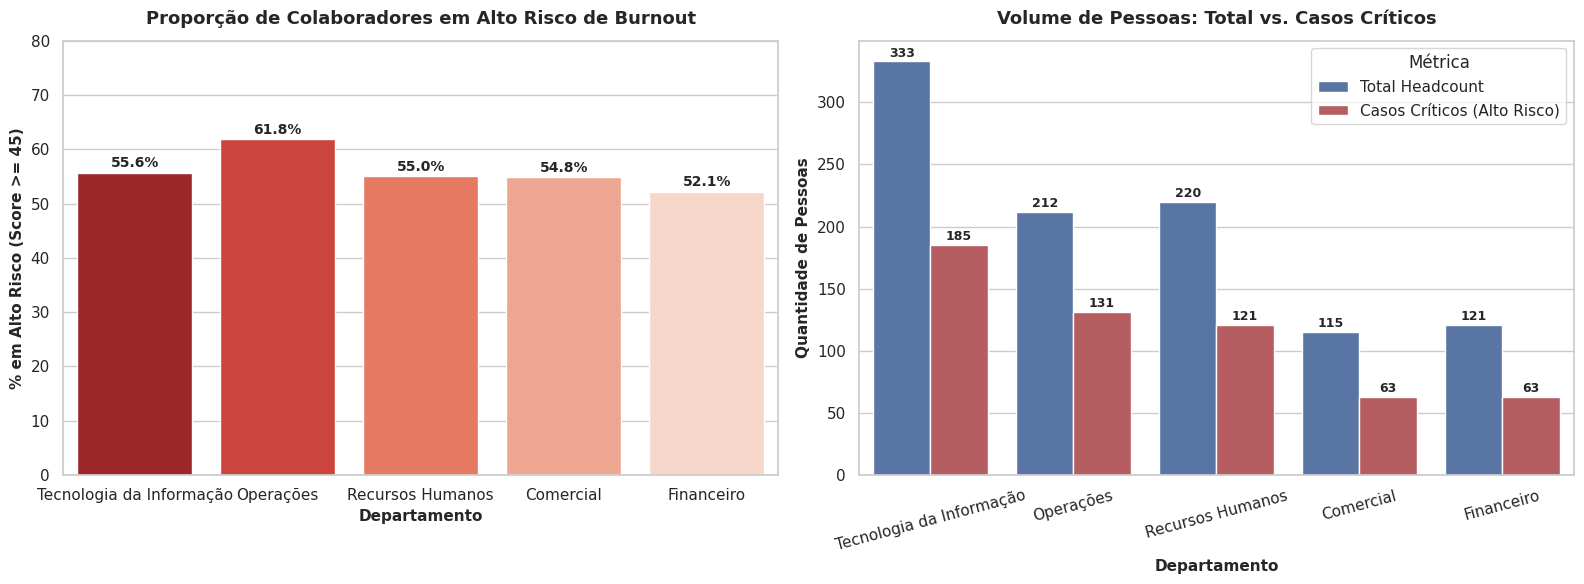

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# 1. Conversão do Agregado Spark SQL para Pandas DataFrame
df_pandas = spark.sql(query_sql).toPandas()
df_pandas['pct_alto_risco'] = ((df_pandas['qtd_alto_risco'] / df_pandas['total_colaboradores']) * 100).round(1)

# 2. Exibição da Tabela Formatação Executiva com Gradiente de Cores
print("=== TABELA FORMATADA DE RISCO DE BURNOUT POR DEPARTAMENTO ===")
styled_table = df_pandas.style \
    .background_gradient(subset=['pct_alto_risco', 'media_score_risco'], cmap='Reds') \
    .format({'pct_alto_risco': '{:.1f}%', 'media_score_risco': '{:.2f}'}) \
    .set_caption("Resumo Analítico - Impacto do Burnout na Empresa")

display(styled_table)

# 3. Geração do Dashboard Visual de Suporte à Decisão
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Porcentagem em Alto Risco por Setor
ax1 = sns.barplot(
    data=df_pandas,
    x='departamento',
    y='pct_alto_risco',
    palette='Reds_r',
    ax=axes[0]
)
axes[0].set_title('Proporção de Colaboradores em Alto Risco de Burnout', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Departamento', fontsize=11, fontweight='bold')
axes[0].set_ylabel('% em Alto Risco (Score >= 45)', fontsize=11, fontweight='bold')
axes[0].set_ylim(0, 80)

for p in ax1.patches:
    ax1.annotate(f"{p.get_height():.1f}%",
                 (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', xytext=(0, 7),
                 textcoords='offset points', fontweight='bold', fontsize=10)

# Gráfico 2: Volume Absoluto (Total Headcount vs Alto Risco)
df_melted = df_pandas.melt(
    id_vars=['departamento'],
    value_vars=['total_colaboradores', 'qtd_alto_risco'],
    var_name='Métrica',
    value_name='Quantidade'
)
df_melted['Métrica'] = df_melted['Métrica'].map({
    'total_colaboradores': 'Total Headcount',
    'qtd_alto_risco': 'Casos Críticos (Alto Risco)'
})

ax2 = sns.barplot(
    data=df_melted,
    x='departamento',
    y='Quantidade',
    hue='Métrica',
    palette=['#4C72B0', '#C44E52'],
    ax=axes[1]
)
axes[1].set_title('Volume de Pessoas: Total vs. Casos Críticos', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Departamento', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Quantidade de Pessoas', fontsize=11, fontweight='bold')

for p in ax2.patches:
    if p.get_height() > 0:
        ax2.annotate(f"{int(p.get_height())}",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 6),
                     textcoords='offset points', fontweight='bold', fontsize=9)

plt.xticks(rotation=15)
plt.tight_layout()

# Salva o gráfico em alta resolução para inclusão na documentação/slides
plt.savefig('dashboard_burnout_spark.png', dpi=300)
plt.show()

=== ETAPA 4: DATA MINING & MACHINE LEARNING ===
[✓] Acurácia do Modelo Preditivo: 95.02%

--- Relatório de Classificação ---
                   precision    recall  f1-score   support

Baixo/Médio Risco       0.95      0.94      0.94       132
       Alto Risco       0.95      0.96      0.96       169

         accuracy                           0.95       301
        macro avg       0.95      0.95      0.95       301
     weighted avg       0.95      0.95      0.95       301



/tmp/ipykernel_1405/3202126802.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_importancia, x='Importância', y='Atributo', palette='viridis', ax=axes[1])


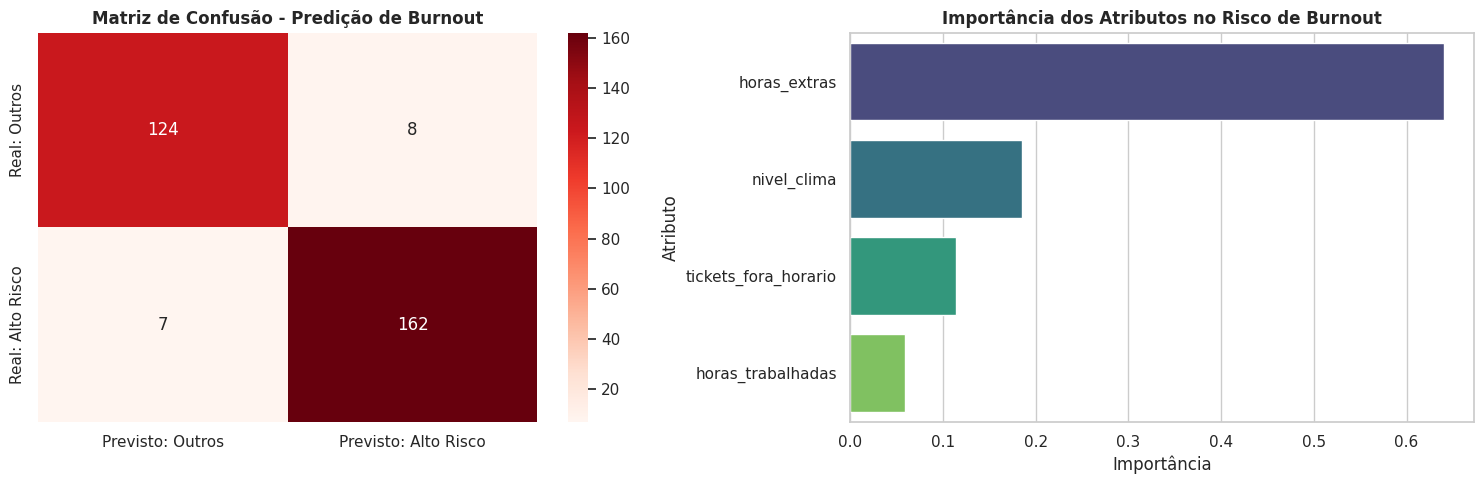

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("=== ETAPA 4: DATA MINING & MACHINE LEARNING ===")

# 1. Preparação dos dados para treinamento do modelo preditivo
df_ml = df_transformed.toPandas()
df_ml['alvo_alto_risco'] = (df_ml['categoria_risco'] == 'Alto Risco').astype(int)

features = ['horas_extras', 'horas_trabalhadas', 'tickets_fora_horario', 'nivel_clima']
X = df_ml[features]
y = df_ml['alvo_alto_risco']

# 2. Divisão estratificada em Treino (70%) e Teste (30%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# 3. Treinamento do Classificador Random Forest
model_rf = RandomForestClassifier(n_estimators=100, random_state=42)
model_rf.fit(X_train, y_train)

y_pred = model_rf.predict(X_test)
acuracia = accuracy_score(y_test, y_pred)

print(f"[✓] Acurácia do Modelo Preditivo: {acuracia * 100:.2f}%\n")
print("--- Relatório de Classificação ---")
print(classification_report(y_test, y_pred, target_names=['Baixo/Médio Risco', 'Alto Risco']))

# 4. Exibição da Matriz de Confusão e Importância das Variáveis
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', ax=axes[0],
            xticklabels=['Previsto: Outros', 'Previsto: Alto Risco'],
            yticklabels=['Real: Outros', 'Real: Alto Risco'])
axes[0].set_title('Matriz de Confusão - Predição de Burnout', fontsize=12, fontweight='bold')

df_importancia = pd.DataFrame({
    'Atributo': features,
    'Importância': model_rf.feature_importances_
}).sort_values(by='Importância', ascending=False)

sns.barplot(data=df_importancia, x='Importância', y='Atributo', palette='viridis', ax=axes[1])
axes[1].set_title('Importância dos Atributos no Risco de Burnout', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('machine_learning_burnout.png', dpi=300)
plt.show()

In [9]:
import time

# 1. Avaliação de Performance do Spark para Escalar Grandes Volumes
start_time = time.time()
df_transformed.groupBy("departamento").agg({"score_risco_burnout": "avg"}).collect()
tempo_execucao = time.time() - start_time

print("=== MÉTRICAS DE DESEMPENHO E PERFORMANCE ===")
print(f"Tempo de execução distribuída no Spark: {tempo_execucao:.4f} segundos\n")

# 2. Persistência dos Dados Processados na Camada Gold do Data Lake
df_resumo_dept.coalesce(1).write.mode("overwrite").option("header", "true").csv("gold/resumo_por_departamento_spark")
df_transformed.write.mode("overwrite").parquet("gold/dados_burnout_processados.parquet")

print("[✓] Resultados persistidos com sucesso na camada Gold (formatos CSV e Parquet)!")

=== MÉTRICAS DE DESEMPENHO E PERFORMANCE ===
Tempo de execução distribuída no Spark: 1.0159 segundos

[✓] Resultados persistidos com sucesso na camada Gold (formatos CSV e Parquet)!


## 📌 Conclusões Executivas & Recomendações de RH

Com base no processamento analítico e preditivo realizado via **Apache Spark** e **Machine Learning** sobre o Data Lake corporativo:

1. **Gargalo Crítico em TI:** Conforme o diagnóstico da Camada Silver do Data Lake, o setor de **Tecnologia da Informação** concentra o maior volume absoluto de colaboradores em **Alto Risco de Burnout (185 pessoas / 55,6% do setor)**, impulsionado pela alta frequência de acionamentos fora do horário comercial.
2. **Alta Intensidade em Operações:** De acordo com os dados agregados da Camada Gold, o setor de **Operações** registrou o maior score médio de risco (**48,84**), mantendo 61,8% da equipe em situação crítica.
3. **Fator Preditivo Principal:** A análise de importância de atributos do modelo Random Forest revelou que as **Horas Extras** e os **Tickets Fora de Horário** representam os principais fatores no diagnóstico de esgotamento na empresa.
4. **Recomendações Estratégicas (ODS 8 da ONU):**
   * Reestruturar as escalas de sobreaviso e regime de plantão no setor de TI.
   * Estabelecer teto diário de horas extras operacionais.
   * Implementar plano de acompanhamento psicológico e preventivo com o RH para os colaboradores rotulados em Alto Risco.